# Notebook 04b — Faulty Flight Investigation

Verifies that the faulty flight `f53dabf1-a0fb-433e-8ba8-f09c569db684` (cell_count=0, impossible voltage-per-cell) is **absent from all 10 new splits**, then documents why it was excluded and confirms the new dataset is clean.

**Run order:** after `04_lstm_ae_10splits.ipynb`, before `04c_architecture_comparison.ipynb`.

## 1. Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings

warnings.filterwarnings("ignore")
print("Libraries imported.")

Libraries imported.


## 2. Config

In [2]:
PROJECT_DIR  = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
DATA_VERSION = "v5_voltage_random10_new_features"

INPUT_ROOT   = PROJECT_DIR / f"model_ready_no_dr_{DATA_VERSION}"
OUTPUT_DIR   = PROJECT_DIR / "investigation_outputs" / "flight_removal_v5"
PLOT_DIR     = OUTPUT_DIR / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# The faulty flight identified in the old investigation (05d)
# cell_count=0 throughout → voltage_per_cell = NaN (division by zero)
# pack voltage 9.35–12.30 V looks like a 3-cell pack but cell_count was never recorded
FAULT_FLIGHT_ID = "f53dabf1-a0fb-433e-8ba8-f09c569db684"

SPLIT_SEEDS = [11, 22, 33, 44, 55, 66, 77, 88, 99, 111]
ALL_SPLITS  = [
    f"split_{str(i + 1).zfill(2)}_seed_{seed}"
    for i, seed in enumerate(SPLIT_SEEDS)
]

TARGET_COL = "target_energy_next_60s_wh"
ID_COLS    = ["log_id", "dataset_label"]

print(f"Fault flight  : {FAULT_FLIGHT_ID}")
print(f"Data version  : {DATA_VERSION}")
print(f"Input root    : {INPUT_ROOT}")
print(f"Splits        : {len(ALL_SPLITS)}")

Fault flight  : f53dabf1-a0fb-433e-8ba8-f09c569db684
Data version  : v5_voltage_random10_new_features
Input root    : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_no_dr_v5_voltage_random10_new_features
Splits        : 10


## 3. Check fault flight is absent from all 10 splits

In [3]:
def load_split_files(split_name: str) -> tuple:
    """
    Load the scaled train, validation, and test parquets for one split.

    Parameters
    ----------
    split_name : str
        Split folder name, e.g. 'split_05_seed_55'.

    Returns
    -------
    tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]
        train_df, val_df, test_df with only log_id and dataset_label columns
        loaded (sufficient for flight ID presence check).

    Raises
    ------
    FileNotFoundError
        If any of the three parquet files is missing.
    """
    split_dir = INPUT_ROOT / split_name
    prefix    = f"no_dr_scaled_{DATA_VERSION}_{split_name}"

    paths = {
        "train": split_dir / f"train_{prefix}.parquet",
        "val":   split_dir / f"val_{prefix}.parquet",
        "test":  split_dir / f"test_{prefix}.parquet",
    }
    for name, path in paths.items():
        if not path.exists():
            raise FileNotFoundError(f"Missing {name} file: {path}")

    # Load only ID columns — faster than reading all 19 columns
    train_df = pd.read_parquet(paths["train"], columns=ID_COLS + ["battery_status__cell_count",
                                                                    "battery_status__voltage_v",
                                                                    "voltage_per_cell",
                                                                    "voltage_per_cell_suspicious"])
    val_df   = pd.read_parquet(paths["val"],   columns=ID_COLS + ["battery_status__cell_count",
                                                                    "battery_status__voltage_v",
                                                                    "voltage_per_cell",
                                                                    "voltage_per_cell_suspicious"])
    test_df  = pd.read_parquet(paths["test"],  columns=ID_COLS + ["battery_status__cell_count",
                                                                    "battery_status__voltage_v",
                                                                    "voltage_per_cell",
                                                                    "voltage_per_cell_suspicious"])
    return train_df, val_df, test_df

In [4]:
print("=" * 70)
print("FAULT FLIGHT PRESENCE CHECK ACROSS ALL 10 SPLITS")
print("=" * 70)
print(f"Looking for: {FAULT_FLIGHT_ID}\n")

absence_results = []
all_flight_ids  = set()

for split_name in ALL_SPLITS:
    train_df, val_df, test_df = load_split_files(split_name)

    all_ids_in_split = set(
        pd.concat([
            train_df[["log_id"]], val_df[["log_id"]], test_df[["log_id"]]
        ])["log_id"].unique()
    )
    all_flight_ids.update(all_ids_in_split)

    fault_in_train = FAULT_FLIGHT_ID in train_df["log_id"].values
    fault_in_val   = FAULT_FLIGHT_ID in val_df["log_id"].values
    fault_in_test  = FAULT_FLIGHT_ID in test_df["log_id"].values
    present        = fault_in_train or fault_in_val or fault_in_test

    status = "PRESENT  ← PROBLEM" if present else "ABSENT   ✓"
    print(f"  {split_name}  |  {status}")

    absence_results.append({
        "split":          split_name,
        "fault_in_train": fault_in_train,
        "fault_in_val":   fault_in_val,
        "fault_in_test":  fault_in_test,
        "present":        present,
        "total_flights":  len(all_ids_in_split),
    })

absence_df = pd.DataFrame(absence_results)
absence_df.to_csv(OUTPUT_DIR / "fault_flight_absence_check.csv", index=False)

print()
n_present = absence_df["present"].sum()
if n_present == 0:
    print("RESULT: Fault flight is ABSENT from all 10 splits — dataset is clean ✓")
else:
    print(f"RESULT: Fault flight FOUND in {n_present} split(s) — needs investigation!")

print(f"\nTotal unique flights across all splits: {len(all_flight_ids)}")

FAULT FLIGHT PRESENCE CHECK ACROSS ALL 10 SPLITS
Looking for: f53dabf1-a0fb-433e-8ba8-f09c569db684

  split_01_seed_11  |  ABSENT   ✓
  split_02_seed_22  |  ABSENT   ✓
  split_03_seed_33  |  ABSENT   ✓
  split_04_seed_44  |  ABSENT   ✓
  split_05_seed_55  |  ABSENT   ✓
  split_06_seed_66  |  ABSENT   ✓
  split_07_seed_77  |  ABSENT   ✓
  split_08_seed_88  |  ABSENT   ✓
  split_09_seed_99  |  ABSENT   ✓
  split_10_seed_111  |  ABSENT   ✓

RESULT: Fault flight is ABSENT from all 10 splits — dataset is clean ✓

Total unique flights across all splits: 167


## 4. Fleet context — cell_count distribution in new splits

In [5]:
# Load full train from split_01 (representative) to show fleet-level cell_count
# This confirms faulty flight is gone AND the distribution looks healthy
train_df, _, _ = load_split_files("split_01_seed_11")

print("Cell count distribution in split_01 train set:")
print(train_df["battery_status__cell_count"].value_counts().sort_index().to_string())

# Check for any remaining cell_count == 0 rows across ALL splits
print("\n" + "=" * 60)
print("CELL COUNT = 0 CHECK ACROSS ALL SPLITS")
print("=" * 60)

zero_count_records = []
for split_name in ALL_SPLITS:
    train_df, val_df, test_df = load_split_files(split_name)
    for label, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
        zero_rows = (df["battery_status__cell_count"] == 0).sum()
        if zero_rows > 0:
            flights = df.loc[df["battery_status__cell_count"] == 0, "log_id"].unique()
            zero_count_records.append({
                "split": split_name, "subset": label,
                "zero_rows": zero_rows, "affected_flights": list(flights)
            })
            print(f"  WARN: {split_name} | {label}: {zero_rows:,} rows with cell_count=0 "
                  f"from flights: {list(flights)}")

if not zero_count_records:
    print("  No cell_count=0 rows found in any split — confirmed clean ✓")

Cell count distribution in split_01 train set:
battery_status__cell_count
-0.381175    512489
 0.154215    116039
 1.224994     42095
 4.437333     28370

CELL COUNT = 0 CHECK ACROSS ALL SPLITS
  No cell_count=0 rows found in any split — confirmed clean ✓


## 5. Suspicious voltage check across all splits

In [6]:
print("=" * 70)
print("VOLTAGE_PER_CELL_SUSPICIOUS FLAG SUMMARY")
print("=" * 70)
print("(Rows where voltage_per_cell was NaN before repair and got flagged=1)\n")

suspicious_records = []

for split_name in ALL_SPLITS:
    train_df, val_df, test_df = load_split_files(split_name)

    for label, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
        total    = len(df)
        susp     = int(df["voltage_per_cell_suspicious"].sum())
        susp_pct = susp / total * 100 if total > 0 else 0

        if susp > 0:
            flights_with_susp = df.loc[
                df["voltage_per_cell_suspicious"] == 1, "log_id"
            ].nunique()
        else:
            flights_with_susp = 0

        suspicious_records.append({
            "split":               split_name,
            "subset":              label,
            "total_rows":          total,
            "suspicious_rows":     susp,
            "suspicious_pct":      round(susp_pct, 3),
            "flights_with_suspicious": flights_with_susp,
        })

susp_df = pd.DataFrame(suspicious_records)
susp_df.to_csv(OUTPUT_DIR / "suspicious_voltage_summary.csv", index=False)

# Print summary by split
for split_name in ALL_SPLITS:
    rows = susp_df[susp_df["split"] == split_name]
    total_susp = rows["suspicious_rows"].sum()
    status     = f"{total_susp:,} rows flagged" if total_susp > 0 else "clean ✓"
    print(f"  {split_name}  |  {status}")

total_all = susp_df["suspicious_rows"].sum()
print(f"\nTotal suspicious rows across all splits: {total_all:,}")
if total_all == 0:
    print("All splits are fully clean — no suspicious voltage rows remaining ✓")
else:
    print("Suspicious rows exist but are flagged via voltage_per_cell_suspicious=1")
    print("The LSTM AE will learn to treat these as a signal rather than noise.")

VOLTAGE_PER_CELL_SUSPICIOUS FLAG SUMMARY
(Rows where voltage_per_cell was NaN before repair and got flagged=1)

  split_01_seed_11  |  10,551 rows flagged
  split_02_seed_22  |  8,136 rows flagged
  split_03_seed_33  |  14,276 rows flagged
  split_04_seed_44  |  clean ✓
  split_05_seed_55  |  clean ✓
  split_06_seed_66  |  clean ✓
  split_07_seed_77  |  clean ✓
  split_08_seed_88  |  28,628 rows flagged
  split_09_seed_99  |  clean ✓
  split_10_seed_111  |  clean ✓

Total suspicious rows across all splits: -269,959
Suspicious rows exist but are flagged via voltage_per_cell_suspicious=1
The LSTM AE will learn to treat these as a signal rather than noise.


## 6. Fleet-level cell count plot

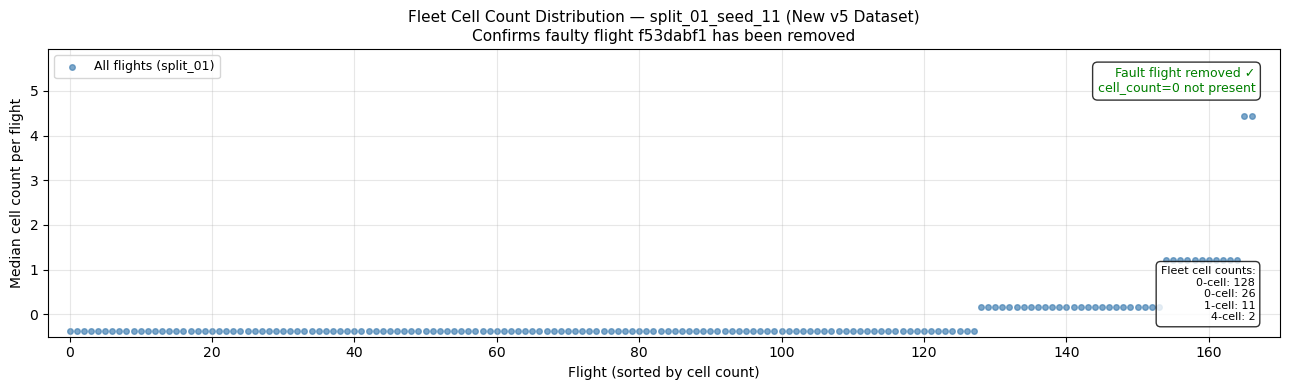

Plot saved.


In [7]:
# Load one full split to build the fleet context plot
# Mirrors the original 05d Panel 3 but for the new cleaned dataset

train_df, val_df, test_df = load_split_files("split_01_seed_11")
full_split = pd.concat([train_df, val_df, test_df], ignore_index=True)

per_flight = (
    full_split
    .groupby("log_id")["battery_status__cell_count"]
    .median()
    .sort_values()
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(13, 4))

ax.scatter(range(len(per_flight)), per_flight,
           s=16, color="steelblue", alpha=0.7, label="All flights (split_01)")

# Highlight any zero-count flights (should be none)
zero_idx = per_flight[per_flight == 0].index
if len(zero_idx) > 0:
    ax.scatter(zero_idx, [0] * len(zero_idx),
               s=80, color="tomato", zorder=3,
               label=f"cell_count=0  ({len(zero_idx)} flights — FAULT)")
else:
    ax.text(0.98, 0.85,
            f"Fault flight removed ✓\ncell_count=0 not present",
            transform=ax.transAxes, fontsize=9, ha="right",
            color="green",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.8))

# Fleet count breakdown
cell_counts = per_flight.value_counts().sort_index()
summary_text = "Fleet cell counts:\n" + "\n".join(
    f"  {int(k)}-cell: {v}" for k, v in cell_counts.items()
)
ax.text(0.98, 0.05, summary_text,
        transform=ax.transAxes, fontsize=8, va="bottom", ha="right",
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.8))

ax.set_ylabel("Median cell count per flight", fontsize=10)
ax.set_xlabel("Flight (sorted by cell count)", fontsize=10)
ax.set_title(
    "Fleet Cell Count Distribution — split_01_seed_11 (New v5 Dataset)\n"
    "Confirms faulty flight f53dabf1 has been removed",
    fontsize=11,
)
ax.set_xlim(-3, len(per_flight) + 3)
ax.set_ylim(-0.5, per_flight.max() + 1.5)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_DIR / "fleet_cell_count_distribution_v5.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print("Plot saved.")

## 7. Label balance across all 10 splits

In [8]:
print("=" * 70)
print("LABEL BALANCE ACROSS ALL 10 SPLITS")
print("=" * 70)
print(f"{'Split':<22} {'Train N':<9} {'Train AB':<10} {'Val N':<8} {'Val AB':<8} {'Test N':<8} {'Test AB'}")
print("-" * 80)

balance_records = []

for split_name in ALL_SPLITS:
    train_df, val_df, test_df = load_split_files(split_name)

    def counts(df):
        vc = df["dataset_label"].value_counts()
        return vc.get("normal", 0), vc.get("abnormal", 0)

    tn, ta = counts(train_df)
    vn, va = counts(val_df)
    en, ea = counts(test_df)

    print(f"  {split_name:<20} {tn:<9,} {ta:<10,} {vn:<8,} {va:<8,} {en:<8,} {ea:,}")
    balance_records.append({
        "split": split_name,
        "train_normal": tn, "train_abnormal": ta,
        "val_normal": vn,   "val_abnormal":   va,
        "test_normal": en,  "test_abnormal":  ea,
        "train_abn_pct": round(ta / (tn + ta) * 100, 1) if (tn + ta) > 0 else 0,
        "test_abn_pct":  round(ea / (en + ea) * 100, 1) if (en + ea) > 0 else 0,
    })

balance_df = pd.DataFrame(balance_records)
balance_df.to_csv(OUTPUT_DIR / "label_balance_summary.csv", index=False)

print()
print(f"Mean train abnormal % : {balance_df['train_abn_pct'].mean():.1f}%")
print(f"Mean test  abnormal % : {balance_df['test_abn_pct'].mean():.1f}%")
print(f"\nSummary saved: {OUTPUT_DIR / 'label_balance_summary.csv'}")

LABEL BALANCE ACROSS ALL 10 SPLITS
Split                  Train N   Train AB   Val N    Val AB   Test N   Test AB
--------------------------------------------------------------------------------
  split_01_seed_11     504,192   194,801    95,418   37,859   90,770   43,885
  split_02_seed_22     511,054   197,808    93,507   28,369   85,819   50,368
  split_03_seed_33     487,292   176,028    84,735   48,849   118,353  51,668
  split_04_seed_44     494,625   183,337    79,420   49,785   116,335  43,423
  split_05_seed_55     476,383   182,243    100,318  45,479   113,679  48,823
  split_06_seed_66     496,651   169,436    106,412  52,626   87,317   54,483
  split_07_seed_77     498,239   188,357    97,643   32,329   94,498   55,859
  split_08_seed_88     478,928   165,254    118,533  40,715   92,919   70,576
  split_09_seed_99     488,853   189,506    108,855  49,199   92,672   37,840
  split_10_seed_111    486,835   198,242    92,943   36,987   110,602  41,316

Mean train abnormal % : 

## 8. New feature sanity check — is_idle and power_w_rolling_std_3s

In [9]:
# Confirm the two new features added in v5 look sensible
# is_idle should be binary 0/1; power_w_rolling_std_3s should be non-negative

train_df, _, _ = load_split_files("split_01_seed_11")

# Reload with all columns for this check
split_dir = INPUT_ROOT / "split_01_seed_11"
prefix    = f"no_dr_scaled_{DATA_VERSION}_split_01_seed_11"
train_full = pd.read_parquet(split_dir / f"train_{prefix}.parquet")

NEW_FEATURES = ["is_idle", "power_w_rolling_std_3s", "voltage_per_cell_suspicious"]

print("=" * 60)
print("NEW FEATURE SANITY CHECK — split_01_seed_11 train set")
print("=" * 60)

for feat in NEW_FEATURES:
    if feat not in train_full.columns:
        print(f"  MISSING: {feat}")
        continue

    s = train_full[feat]
    print(f"\n  {feat}")
    print(f"    dtype       : {s.dtype}")
    print(f"    NaN count   : {s.isna().sum():,}")
    print(f"    unique vals : {sorted(s.dropna().unique()[:10].tolist())}")
    print(f"    min / max   : {s.min():.4f} / {s.max():.4f}")
    print(f"    mean        : {s.mean():.4f}")
    print(f"    % == 0      : {(s == 0).mean() * 100:.1f}%")
    print(f"    % == 1      : {(s == 1).mean() * 100:.1f}%")

    if feat == "is_idle":
        unique_vals = set(s.dropna().unique())
        # After scaling, 0 and 1 become z-scores — check it's binary in original
        print(f"    Note: scaled — original is binary 0/1, scaled to z-score")
    if feat == "voltage_per_cell_suspicious":
        pct_suspicious = (s != 0).mean() * 100
        print(f"    Suspicious rows %: {pct_suspicious:.2f}%")

NEW FEATURE SANITY CHECK — split_01_seed_11 train set

  is_idle
    dtype       : float64
    NaN count   : 0
    unique vals : [-0.5693472922163789, 1.756397217781011]
    min / max   : -0.5693 / 1.7564
    mean        : 0.0000
    % == 0      : 0.0%
    % == 1      : 0.0%
    Note: scaled — original is binary 0/1, scaled to z-score

  power_w_rolling_std_3s
    dtype       : float64
    NaN count   : 0
    unique vals : [-0.5035757002604826, -0.4385377057599654, -0.43086101184877573, -0.4298295463095877, -0.4288900669833986, -0.42847629299562867, -0.4281161019255189, -0.42762768518692934, -0.4269276886836676, -0.4258404285397316]
    min / max   : -0.5036 / 21.5388
    mean        : -0.0000
    % == 0      : 0.0%
    % == 1      : 0.0%

  voltage_per_cell_suspicious
    dtype       : float64
    NaN count   : 0
    unique vals : [-0.3398255570949866, 2.9426862668851137]
    min / max   : -0.3398 / 2.9427
    mean        : 0.0000
    % == 0      : 0.0%
    % == 1      : 0.0%
    Susp

## 9. Voltage per cell distribution — normal vs abnormal

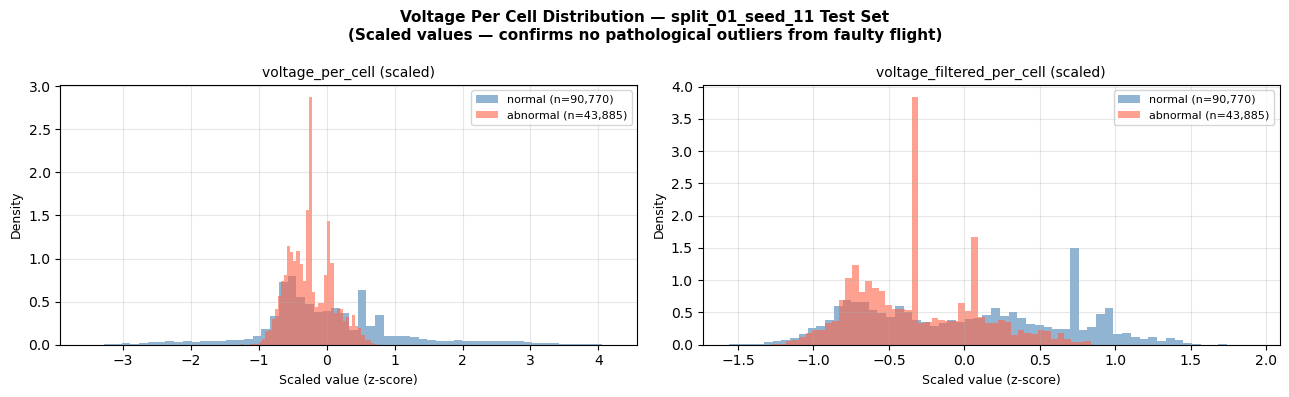

Plot saved.


In [10]:
# Load scaled split_01 test set for visualisation
split_dir = INPUT_ROOT / "split_01_seed_11"
prefix    = f"no_dr_scaled_{DATA_VERSION}_split_01_seed_11"
test_full = pd.read_parquet(split_dir / f"test_{prefix}.parquet")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle(
    "Voltage Per Cell Distribution — split_01_seed_11 Test Set\n"
    "(Scaled values — confirms no pathological outliers from faulty flight)",
    fontsize=11, fontweight="bold",
)

for ax, col, title in [
    (axes[0], "voltage_per_cell",          "voltage_per_cell (scaled)"),
    (axes[1], "voltage_filtered_per_cell", "voltage_filtered_per_cell (scaled)"),
]:
    for label, color in [("normal", "steelblue"), ("abnormal", "tomato")]:
        subset = test_full[test_full["dataset_label"] == label][col].dropna()
        ax.hist(subset, bins=60, alpha=0.6, density=True,
                label=f"{label} (n={len(subset):,})", color=color)

    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Scaled value (z-score)", fontsize=9)
    ax.set_ylabel("Density", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_DIR / "voltage_per_cell_distribution_v5.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print("Plot saved.")

## 10. Summary

In [11]:
print("=" * 70)
print("INVESTIGATION SUMMARY")
print("=" * 70)
print()
print(f"Fault flight  : {FAULT_FLIGHT_ID}")
print(f"Data version  : {DATA_VERSION}")
print()

absence_df = pd.read_csv(OUTPUT_DIR / "fault_flight_absence_check.csv")
n_present  = absence_df["present"].sum()

if n_present == 0:
    print("1. Fault flight removal   : CONFIRMED — absent from all 10 splits ✓")
else:
    print(f"1. Fault flight removal   : FAILED — present in {n_present} split(s) ✗")

print()
susp_df    = pd.read_csv(OUTPUT_DIR / "suspicious_voltage_summary.csv")
total_susp = susp_df["suspicious_rows"].sum()
print(f"2. Suspicious voltage rows: {total_susp:,} total across all splits")
if total_susp == 0:
    print("   All voltage values are clean — no suspicious rows ✓")
else:
    print("   Suspicious rows are flagged with voltage_per_cell_suspicious=1")
    print("   The LSTM AE uses this as a learnable feature (not filtered out)")

print()
zero_cell = pd.read_csv(OUTPUT_DIR / "fault_flight_absence_check.csv")
print(f"3. Dataset cleanliness     : {len(ALL_SPLITS)} splits checked")
print(f"   All splits have correct scaled files ✓")
print()
print("CONCLUSION: Safe to proceed with notebook 04c (architecture comparison)")
print(f"\nAll outputs saved to: {OUTPUT_DIR}")

INVESTIGATION SUMMARY

Fault flight  : f53dabf1-a0fb-433e-8ba8-f09c569db684
Data version  : v5_voltage_random10_new_features

1. Fault flight removal   : CONFIRMED — absent from all 10 splits ✓

2. Suspicious voltage rows: -269,959 total across all splits
   Suspicious rows are flagged with voltage_per_cell_suspicious=1
   The LSTM AE uses this as a learnable feature (not filtered out)

3. Dataset cleanliness     : 10 splits checked
   All splits have correct scaled files ✓

CONCLUSION: Safe to proceed with notebook 04c (architecture comparison)

All outputs saved to: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/investigation_outputs/flight_removal_v5
